## 单斜相 LSTM优化

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 原始数据
L1= [-607.9754, -608.08704, -608.09247, -608.0965, -608.1022, -608.1074, -608.11127, -608.1137, -608.11523, -608.1162, -608.11694, -608.1175, -608.118, -608.11835, -608.1186, -608.11884, -608.11896, -608.11914, -608.1192, -608.11926, -608.1193, -608.1194, -608.1194, -608.11945, -608.11945, -608.11945, -608.11945, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196]
L4= [-607.9053, -608.06384, -608.0803, -608.0758, -608.0842, -608.09595, -608.10455, -608.10974, -608.1127, -608.1144, -608.1155, -608.1162, -608.1168, -608.11725, -608.1176, -608.1179, -608.1182, -608.1184, -608.11865, -608.11884, -608.119, -608.11914, -608.11926, -608.1194, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.1195, -608.1195, -608.1195, -608.1195, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197, -608.1197]
L5= [-607.6849, -607.9989, -608.0422, -608.0724, -608.0857, -608.0964, -608.1046, -608.1103, -608.11383, -608.1157, -608.11664, -608.11694, -608.11707, -608.1171, -608.1171, -608.11725, -608.1174, -608.1175, -608.1177, -608.1179, -608.1181, -608.1183, -608.1184, -608.1186, -608.1187, -608.1188, -608.1189, -608.11896, -608.119, -608.1191, -608.11914, -608.1192, -608.1192, -608.1192, -608.11926, -608.11926, -608.11926, -608.11926, -608.1193, -608.1193, -608.1193, -608.1193, -608.1193, -608.1193, -608.1193, -608.1193, -608.1193, -608.1194, -608.1194, -608.1194, -608.1194, -608.1194, -608.1194, -608.1194, -608.1194, -608.1194, -608.1194, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195]

#L6= [-607.7147, -608.02765, -608.0502, -608.071, -608.0824, -608.0906, -608.09845, -608.1052, -608.11017, -608.11334, -608.1152, -608.1163, -608.117, -608.1175, -608.11786, -608.1181, -608.1184, -608.1186, -608.1188, -608.11896, -608.119, -608.1191, -608.1191, -608.11914, -608.1192, -608.1192, -608.11926, -608.1193, -608.1193, -608.1194, -608.1194, -608.1194, -608.1194, -608.1193, -608.1194, -608.1194, -608.1194, -608.1194, -608.11945, -608.11945, -608.11945, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196]
L6= [-607.3943, -607.9989, -608.0219, -608.0589, -608.0843, -608.0941, -608.0972, -608.09894, -608.1008, -608.1032, -608.10583, -608.1083, -608.1103, -608.1117, -608.1127, -608.1134, -608.114, -608.1146, -608.1152, -608.1156, -608.11597, -608.1163, -608.1165, -608.1167, -608.1169, -608.11707, -608.11725, -608.11743, -608.1176, -608.1178, -608.1179, -608.11804, -608.11816, -608.1183, -608.1184, -608.11847, -608.1185, -608.11865, -608.1187, -608.1188, -608.11884, -608.1189, -608.11896, -608.11896, -608.119, -608.1191, -608.1191, -608.11914, -608.1192, -608.1192, -608.11926, -608.11926, -608.11926, -608.1193, -608.1193, -608.1193, -608.1194, -608.1194, -608.1194, -608.1194, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957]



def process_list(lst):
    """处理列表，使其包含100个元素，截断或填充"""
    if len(lst) >= 50:
        return lst[:50]  # 截断到100个元素
    else:
        # 填充到100个元素，使用最后一个元素重复
        last_value = lst[-1] if lst else 0  # 避免空列表的情况
        return lst + [last_value] * (50 - len(lst))

# 处理列表数据
processed_L1 = process_list(L1)
processed_L4 = process_list(L4)
processed_L5 = process_list(L5)
processed_L6 = process_list(L6)

# 创建画布和坐标轴
plt.figure(figsize=(12, 7))

# 设置中文字体支持
#plt.rcParams["font.family"] = ["SimHei", "WenQuanYi Micro Hei", "Heiti TC"]

# 绘制三条折线
plt.plot(processed_L1, marker='o',color='blue', markersize=4, linestyle='-', linewidth=1.5, label='3 active-space orbitals')
plt.plot(processed_L4, marker='s',color='orange',markersize=4, linestyle='--', linewidth=1.5, label='4 active-space orbitals')
plt.plot(processed_L5, marker='^',color='green', markersize=4, linestyle='-.', linewidth=1.5, label='5 active-space orbitals')
plt.plot(processed_L6, marker='*',color='red', markersize=4, linestyle=':', linewidth=1.5, label='6 active-space orbitals')

# 添加标题和标签
plt.title('Monoclinic ZrO₂', fontsize=15)
plt.xlabel('Step', fontsize=12)
plt.ylabel('Ground State Energy (Hartree)', fontsize=12)

# 添加图例和网格
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)

# 设置y轴范围，突出显示数据差异
# min_val = min(min(processed_L1), min(processed_L4), min(processed_L5))
# max_val = max(max(processed_L1), max(processed_L4), max(processed_L5))
# plt.ylim(min_val - 0.01, max_val + 0.01)

#plt.savefig('fig/MZrO2-orb4.png')
# 显示图形
plt.tight_layout()  # 自动调整布局
plt.show()    

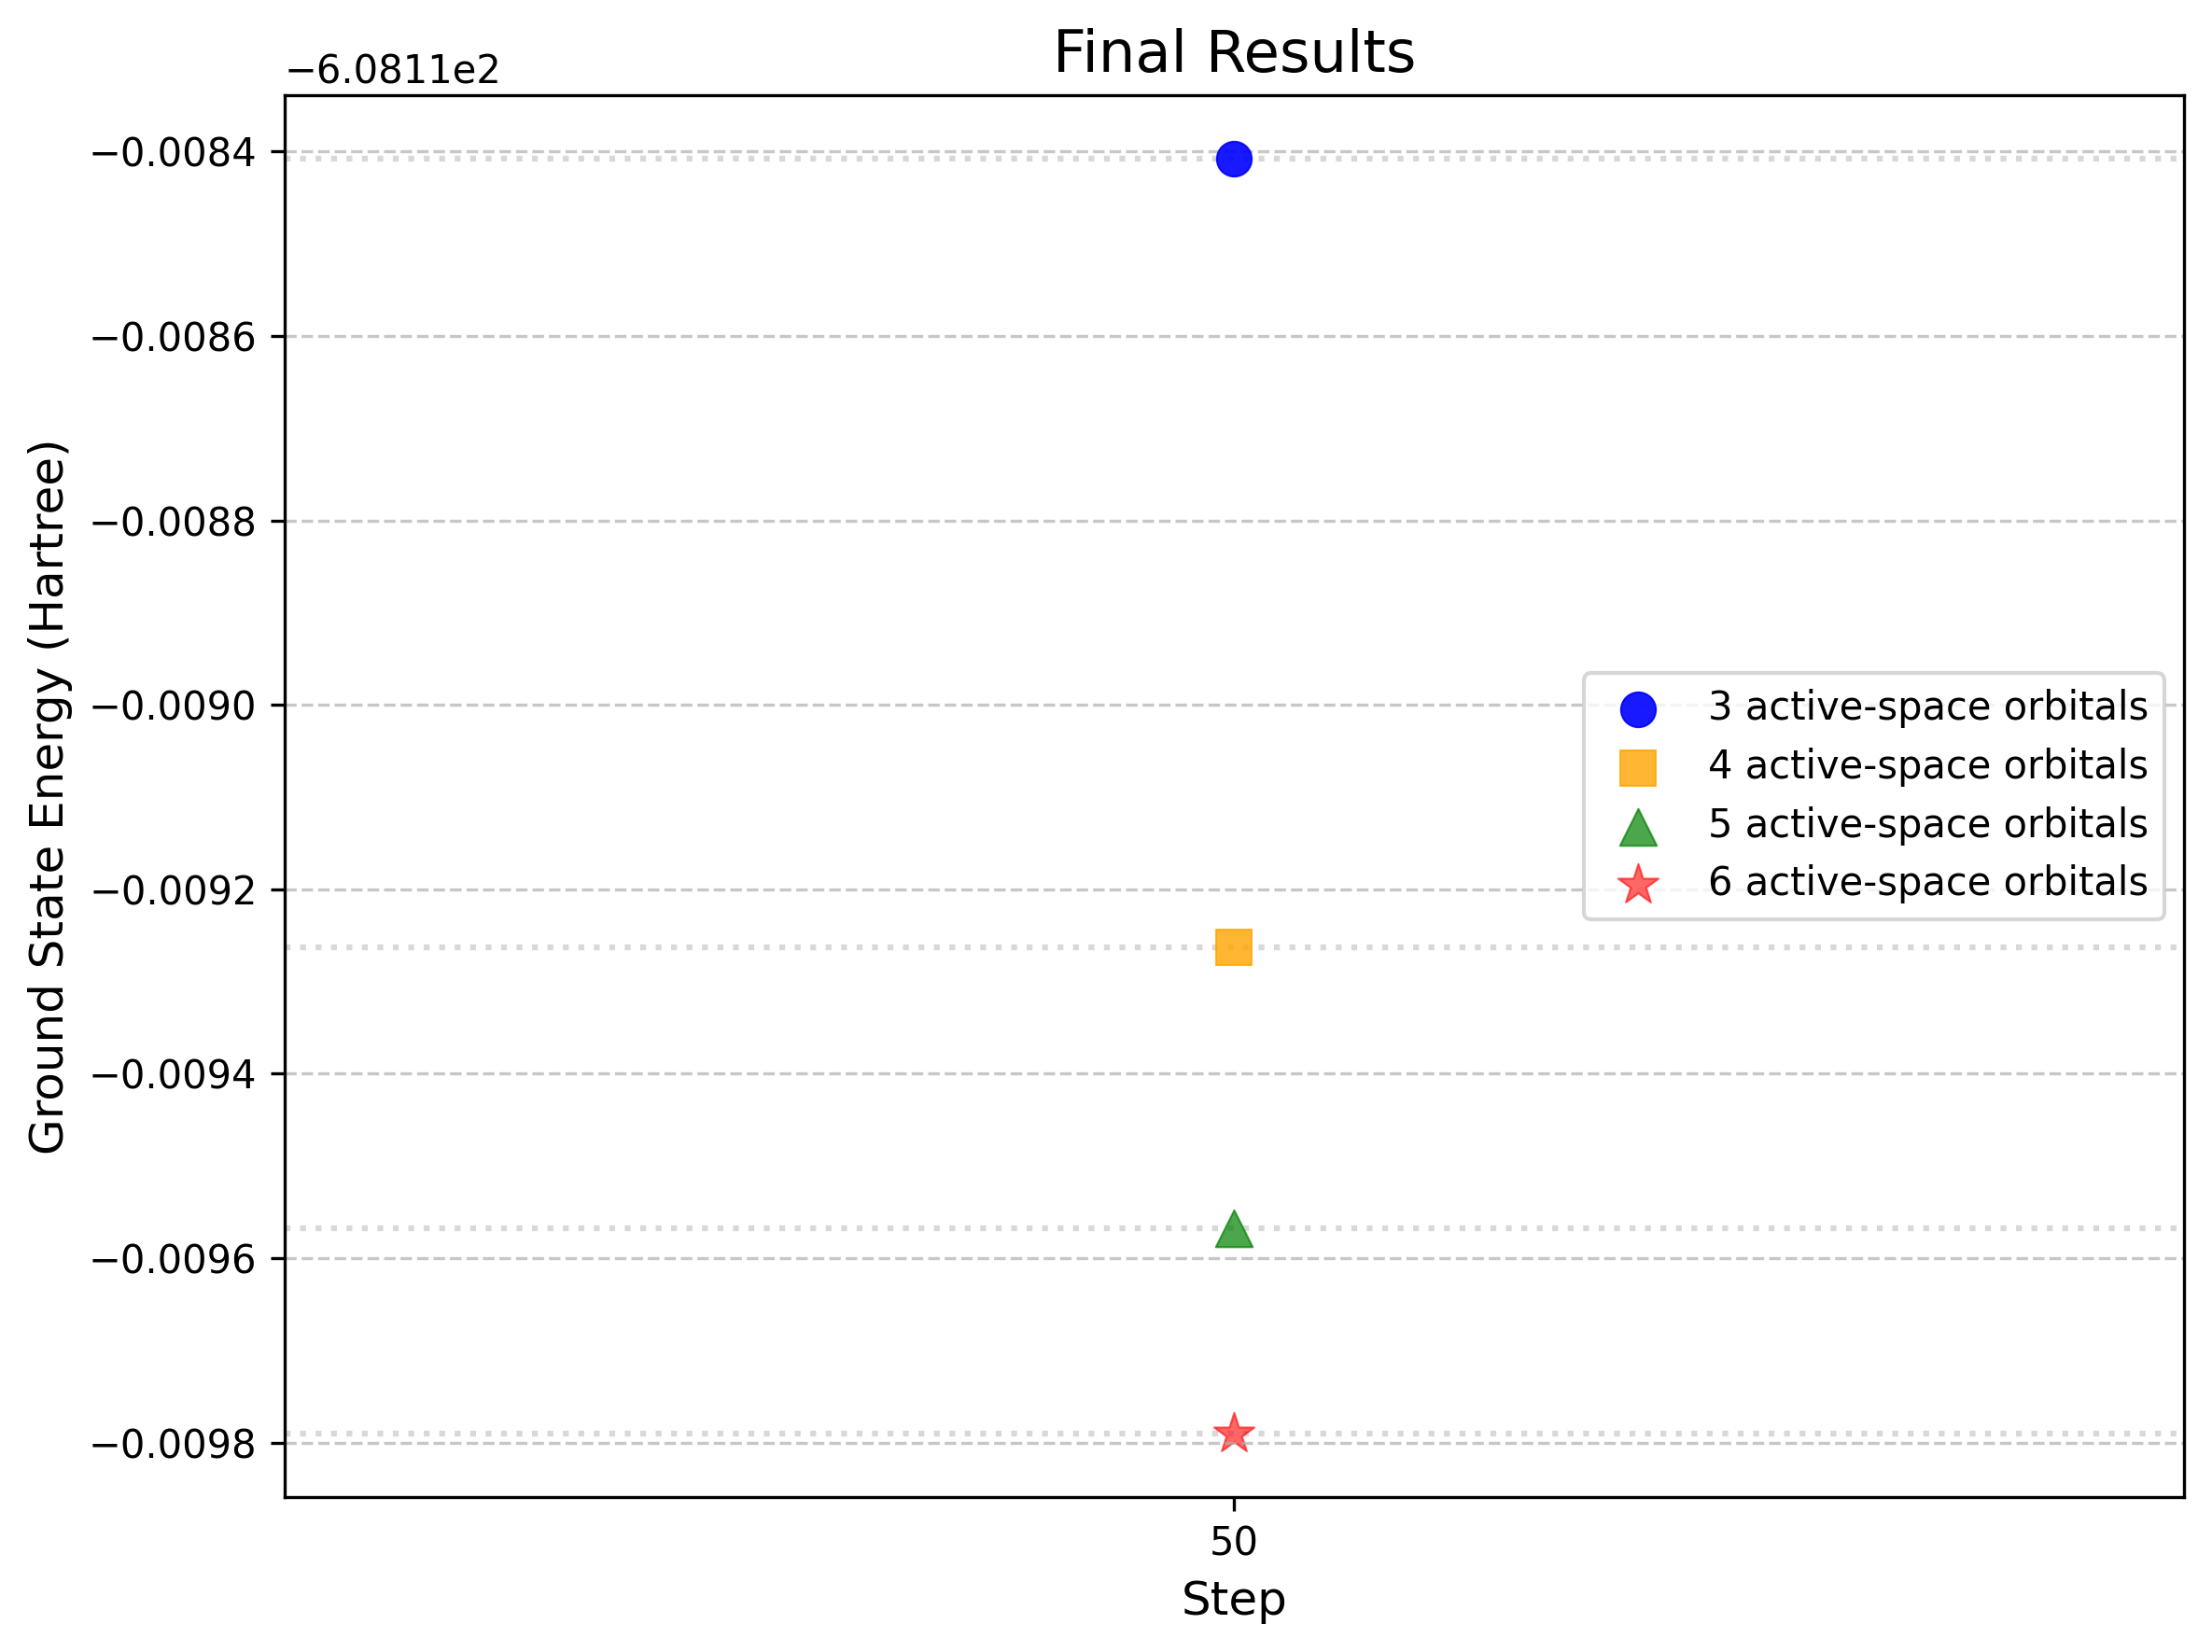

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# 设置图片清晰度
plt.rcParams['figure.dpi'] = 300

# 数据
x_position = 50  # 所有点的横坐标位置
energies = [-608.118408203125, -608.1192626953125, -608.1195678710938, -608.1197899414062]
labels = ['3 active-space orbitals', '4 active-space orbitals', '5 active-space orbitals', '6 active-space orbitals']
colors = ['blue', 'orange', 'green', 'red']
markers = ['o', 's', '^', '*']  # 圆形、正方形、三角形、五角星
sizes = [80, 80, 90, 120]  # 五角星需要更大的尺寸
zorders = [4, 3, 2, 1]  # 控制绘制顺序，确保五角星在最上层
alphas = [0.9, 0.8, 0.7, 0.6]  # 添加透明度，使重叠部分可见

# 创建图形
plt.figure(figsize=(8, 6))

# 绘制每个数据点
for energy, label, color, marker, size, zorder, alpha in zip(energies, labels, colors, markers, sizes, zorders, alphas):
    plt.scatter(x_position, energy, color=color, marker=marker, s=size, label=label, 
                zorder=zorder, alpha=alpha, linewidth=0.5)

# 添加标题和标签
plt.title('Final Results', fontsize=15)
plt.xlabel('Step', fontsize=12)
plt.ylabel('Ground State Energy (Hartree)', fontsize=12)

# 设置x轴刻度
plt.xticks([x_position])
plt.xlim(x_position - 0.1, x_position + 0.1)  # 严格限制x轴范围

# 添加网格和图例
plt.grid(True, linestyle='--', alpha=0.7, axis='y')  # 只显示y轴网格
plt.legend(loc='best')

# 添加水平参考线
for energy in energies:
    plt.axhline(y=energy, linestyle=':', color='gray', alpha=0.3, zorder=0)

# 调整布局
plt.tight_layout()

# 保存图像
# try:
#     plt.savefig('energy_points.png')
#     print("图像已成功保存为 'energy_points.png'")
# except Exception as e:
#     print(f"保存图像时出错: {e}")
#plt.savefig('fig/MZrO2-orb4-1.png')

# 显示图像
plt.show()    

## 四方相

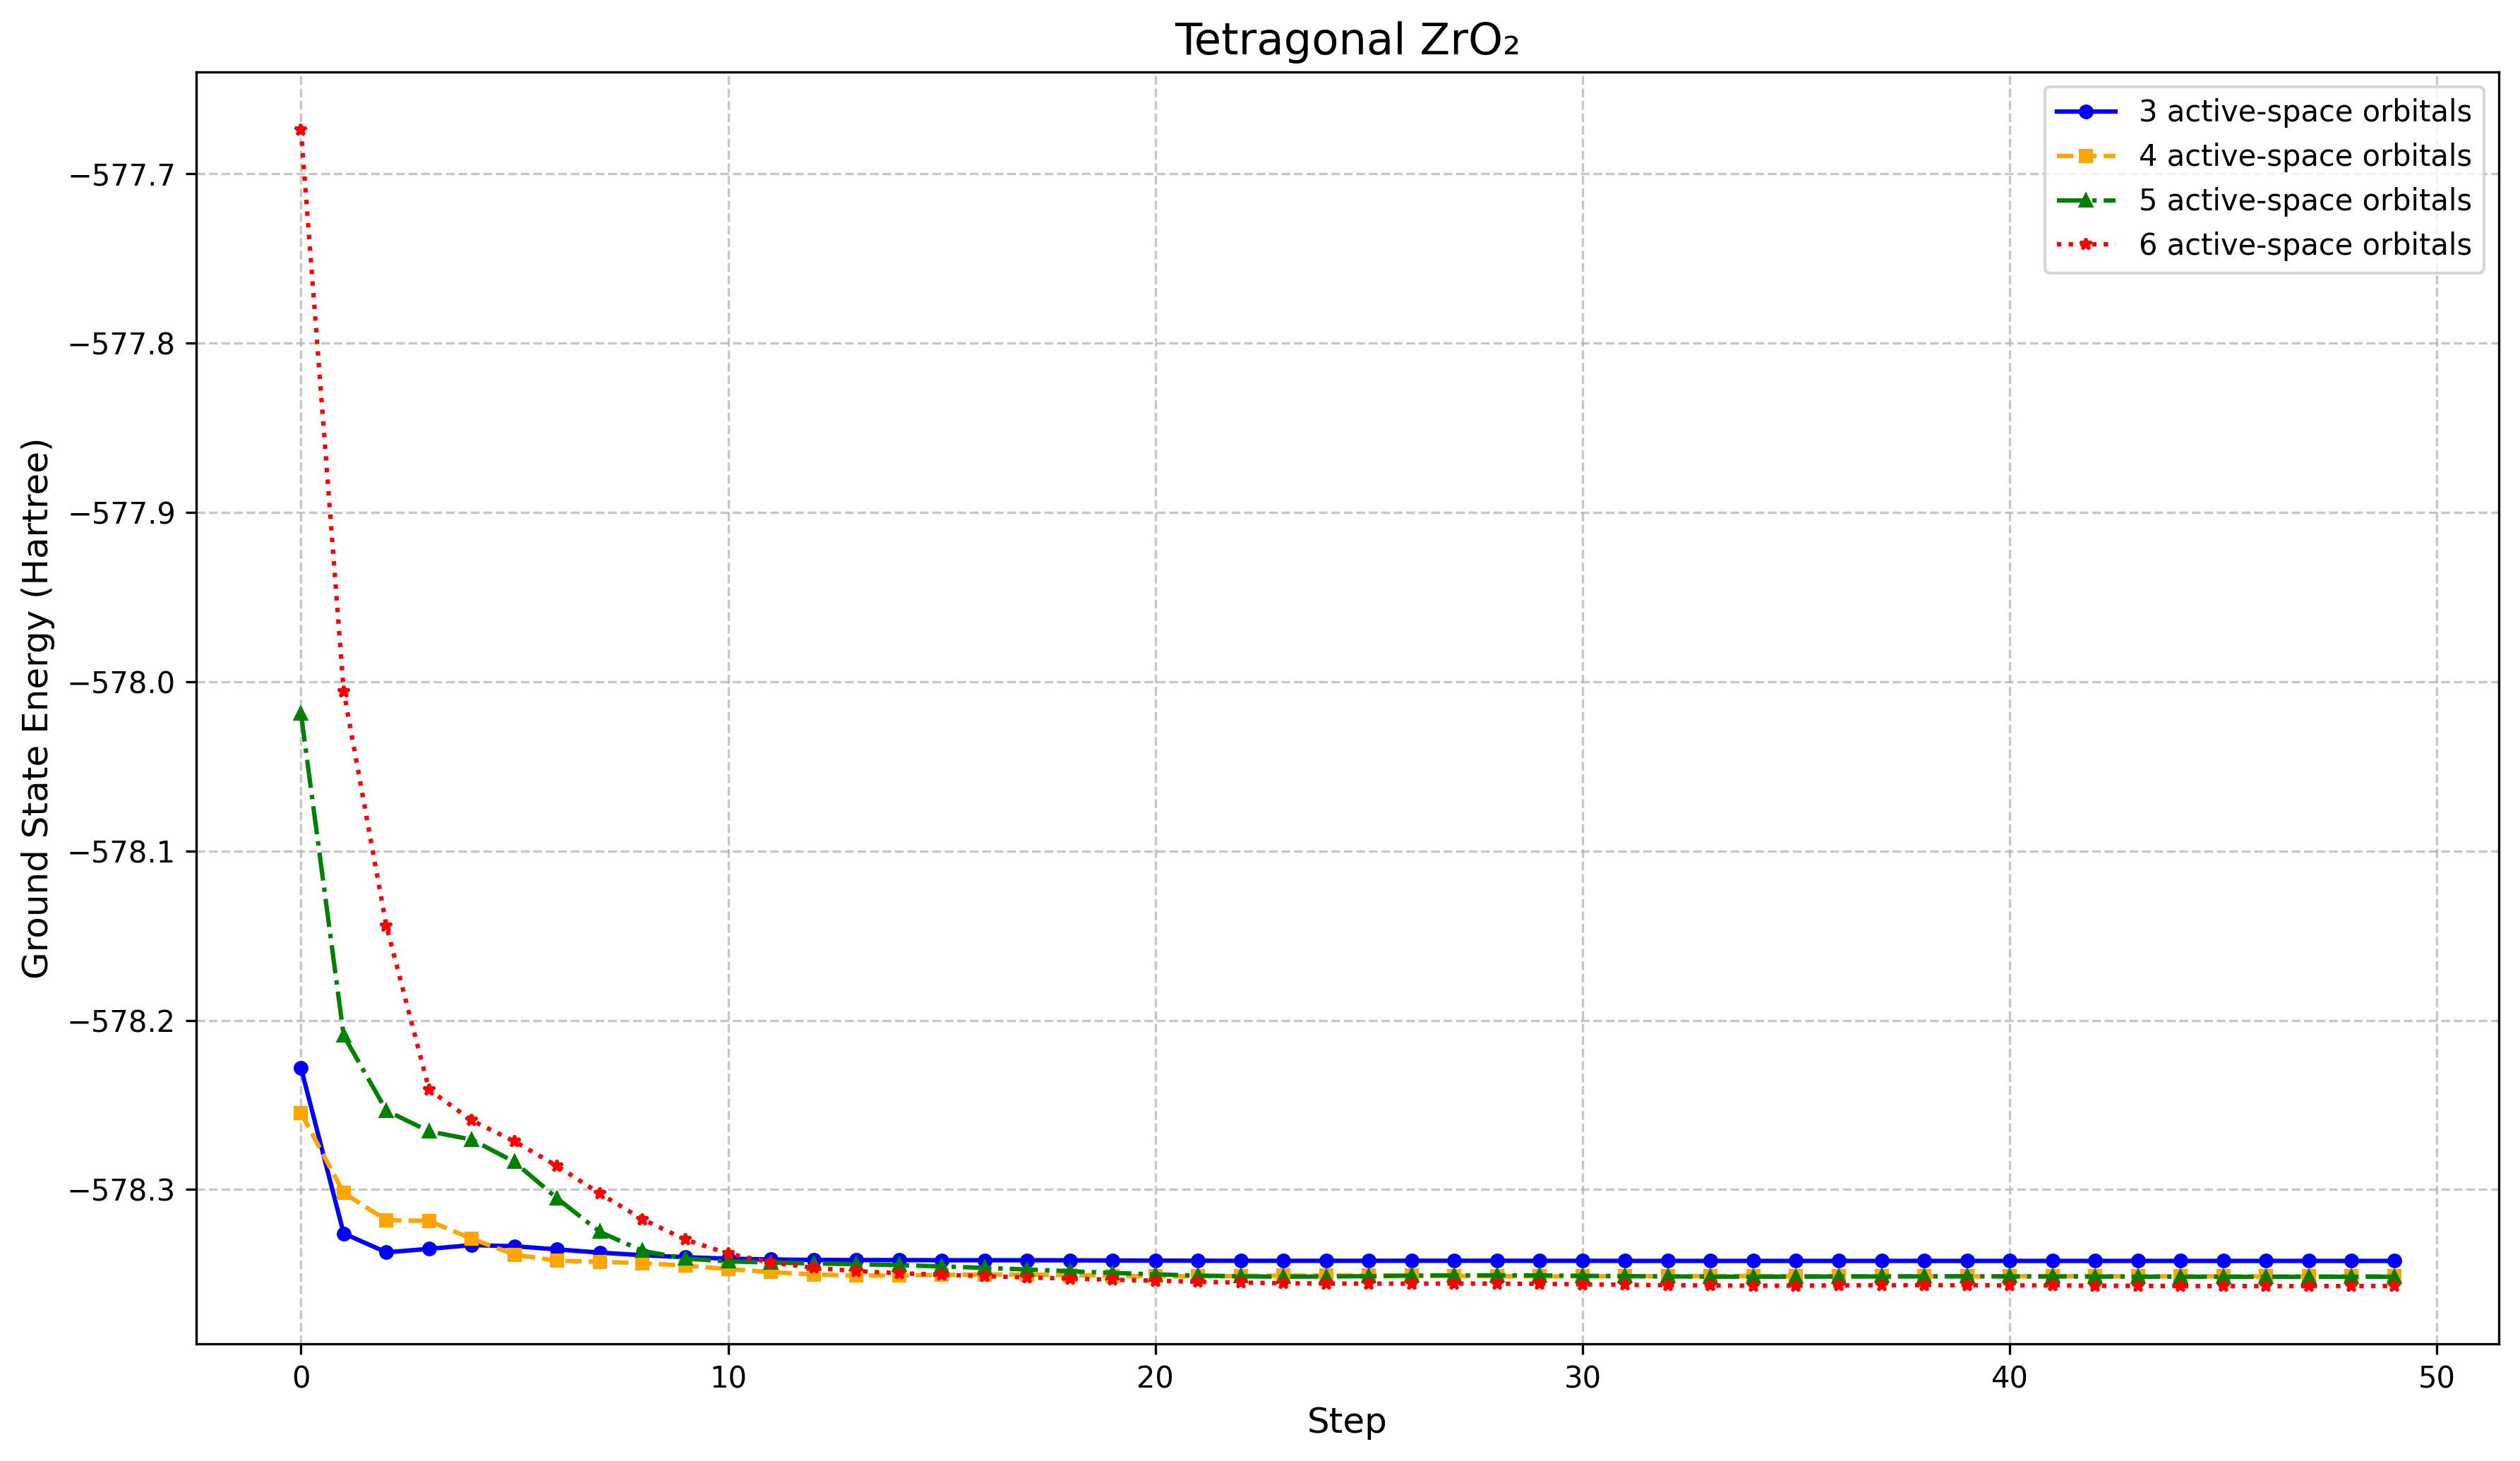

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# 原始数据
L1= [-578.228, -578.32587, -578.33704, -578.33496, -578.33276, -578.33344, -578.3353, -578.3372, -578.33875, -578.3399, -578.34076, -578.34125, -578.3415, -578.3416, -578.3416, -578.3417, -578.3417, -578.3417, -578.34174, -578.34186, -578.3419, -578.342, -578.34204, -578.34204, -578.34204, -578.34204, -578.342, -578.342, -578.342, -578.34204, -578.34204, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.3421, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216, -578.34216]
L4= [-578.2546, -578.30194, -578.31805, -578.3185, -578.329, -578.3384, -578.342, -578.34265, -578.3434, -578.3449, -578.34686, -578.34875, -578.3501, -578.35077, -578.3507, -578.35034, -578.3501, -578.35016, -578.3505, -578.3509, -578.35114, -578.35114, -578.351, -578.3508, -578.35077, -578.3507, -578.3508, -578.35095, -578.3511, -578.3512, -578.3512, -578.35114, -578.3511, -578.351, -578.351, -578.3511, -578.35114, -578.3512, -578.3512, -578.3512, -578.35114, -578.35114, -578.35114, -578.35114, -578.3512, -578.3512, -578.3512, -578.3512, -578.3512, -578.3512]
L5= [-578.01886, -578.209, -578.25336, -578.2656, -578.27045, -578.2837, -578.30524, -578.325, -578.3362, -578.3407, -578.34235, -578.3431, -578.34357, -578.34406, -578.3446, -578.34534, -578.3462, -578.34717, -578.3482, -578.3492, -578.35004, -578.35077, -578.3512, -578.3514, -578.3513, -578.3511, -578.3508, -578.35065, -578.3506, -578.3507, -578.3509, -578.3511, -578.35126, -578.3514, -578.3514, -578.3514, -578.3513, -578.35126, -578.3512, -578.3512, -578.35126, -578.35126, -578.3513, -578.3514, -578.35144, -578.3515, -578.3515, -578.3515, -578.35144, -578.35144, -578.35144, -578.35144, -578.3515, -578.3515, -578.3515, -578.35156, -578.35156, -578.35156, -578.35156, -578.35156, -578.35156, -578.3516, -578.3516, -578.3516, -578.3516, -578.3517, -578.3517, -578.3517, -578.3517, -578.3517, -578.3517, -578.35175, -578.35175, -578.35175, -578.35175, -578.3518, -578.3518, -578.3518, -578.35187, -578.35187, -578.35187, -578.35187, -578.3519, -578.3519, -578.3519, -578.352, -578.352, -578.352, -578.35205, -578.35205, -578.35205, -578.3521, -578.3521, -578.3521, -578.3521, -578.3522, -578.3522, -578.3522, -578.3522, -578.35223]

#L5= [-578.02924, -578.16724, -578.2764, -578.30566, -578.3215, -578.3334, -578.34094, -578.34515, -578.3472, -578.34814, -578.3486, -578.3487, -578.34875, -578.3488, -578.34894, -578.3491, -578.3494, -578.34973, -578.3501, -578.3505, -578.3509, -578.3512, -578.35144, -578.3516, -578.35175, -578.35175, -578.35175, -578.3517, -578.3516, -578.3516, -578.3517, -578.3518, -578.35187, -578.3519, -578.352, -578.35205, -578.352, -578.352, -578.352, -578.3519, -578.352, -578.352, -578.352, -578.35205, -578.35205, -578.3521, -578.3521, -578.3521, -578.3521, -578.35205, -578.3521, -578.3521, -578.3521, -578.3521, -578.3521, -578.3521, -578.3521, -578.3521, -578.3521, -578.3521, -578.3521, -578.3521, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.3522, -578.35223, -578.35223, -578.35223, -578.35223, -578.35223, -578.35223, -578.35223, -578.35223, -578.35223, -578.35223, -578.35223, -578.35223, -578.35223, -578.35223, -578.35223, -578.35223, -578.35223]
L6= [-577.6742, -578.0058, -578.14435, -578.241, -578.25916, -578.27155, -578.28613, -578.30237, -578.31757, -578.32947, -578.33777, -578.343, -578.3462, -578.3481, -578.34937, -578.3503, -578.3511, -578.35187, -578.35254, -578.3532, -578.3538, -578.35443, -578.3549, -578.3553, -578.35547, -578.3555, -578.3555, -578.35547, -578.3555, -578.35565, -578.3559, -578.3562, -578.3565, -578.3566, -578.35675, -578.3567, -578.3566, -578.3565, -578.35645, -578.3565, -578.35657, -578.3566, -578.35675, -578.3568, -578.35693, -578.35693, -578.357, -578.35693, -578.35693, -578.3569, -578.3569, -578.35693, -578.357, -578.35706, -578.3571, -578.3571, -578.3571, -578.3571, -578.3571, -578.3571, -578.3571, -578.3571, -578.3571, -578.3572, -578.3572, -578.3572, -578.3572, -578.3572, -578.3572, -578.3572, -578.3572, -578.3572, -578.3572, -578.35724, -578.35724, -578.35724, -578.3572, -578.3572, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724, -578.35724]




def process_list(lst):
    """处理列表，使其包含100个元素，截断或填充"""
    
    if len(lst) >= 50:
        return lst[:50]  # 截断到100个元素
    else:
        # 填充到100个元素，使用最后一个元素重复
        last_value = lst[-1] if lst else 0  # 避免空列表的情况
        return lst + [last_value] * (50 - len(lst))

# 处理列表数据
processed_L1 = process_list(L1)
processed_L4 = process_list(L4)
processed_L5 = process_list(L5)
processed_L6 = process_list(L6)

# 创建画布和坐标轴
plt.figure(figsize=(12, 7))

# 设置中文字体支持
#plt.rcParams["font.family"] = ["SimHei", "WenQuanYi Micro Hei", "Heiti TC"]

# 绘制三条折线
plt.plot(processed_L1, marker='o',color='blue', markersize=4, linestyle='-', linewidth=1.5, label='3 active-space orbitals')
plt.plot(processed_L4, marker='s',color='orange',markersize=4, linestyle='--', linewidth=1.5, label='4 active-space orbitals')
plt.plot(processed_L5, marker='^',color='green', markersize=4, linestyle='-.', linewidth=1.5, label='5 active-space orbitals')
plt.plot(processed_L6, marker='*',color='red', markersize=4, linestyle=':', linewidth=1.5, label='6 active-space orbitals')


# 添加标题和标签
plt.title('Tetragonal ZrO₂', fontsize=15)
plt.xlabel('Step', fontsize=12)
plt.ylabel('Ground State Energy (Hartree)', fontsize=12)

# 添加图例和网格
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)

# 设置y轴范围，突出显示数据差异
# min_val = min(min(processed_L1), min(processed_L4), min(processed_L5))
# max_val = max(max(processed_L1), max(processed_L4), max(processed_L5))
# plt.ylim(min_val - 0.01, max_val + 0.01)

#plt.savefig('fig/TZrO2-orb2.png')
# 显示图形
plt.tight_layout()  # 自动调整布局
plt.show()    

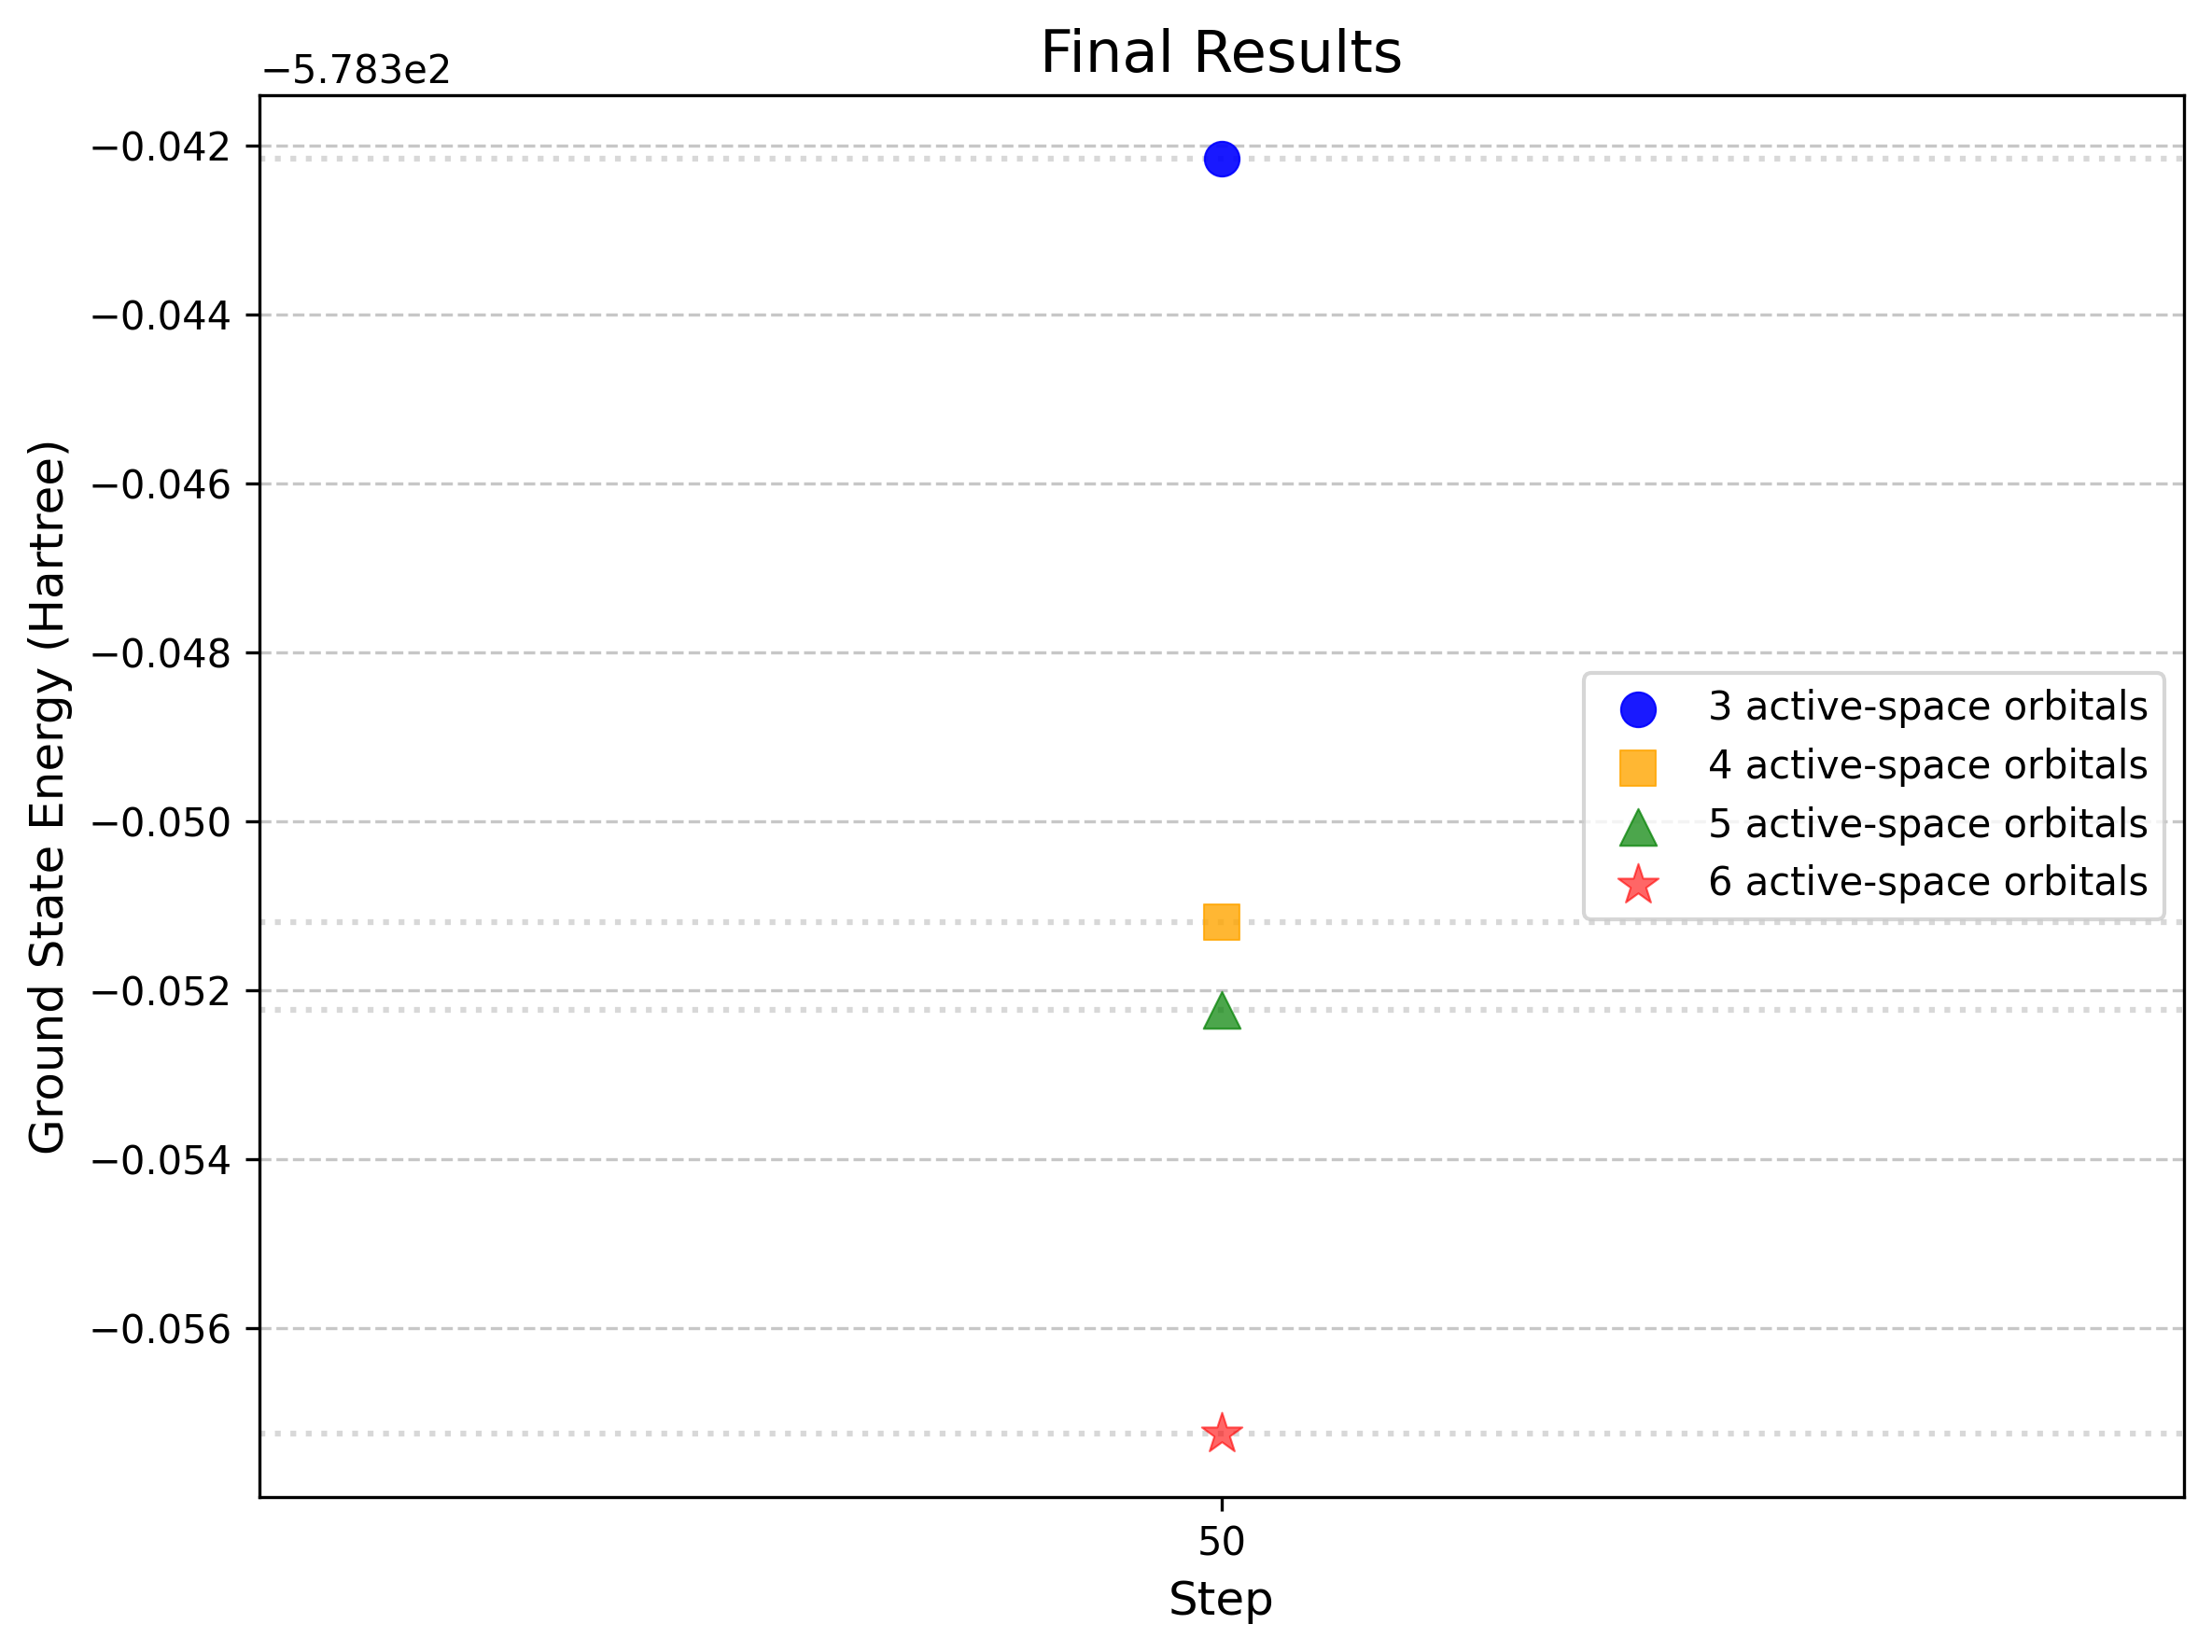

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# 设置图片清晰度
plt.rcParams['figure.dpi'] = 300

# 数据
x_position = 50  # 所有点的横坐标位置
energies = [-578.3421630859375, -578.3511962890625, -578.3522338867188,  -578.3572435937562]
labels = ['3 active-space orbitals', '4 active-space orbitals', '5 active-space orbitals', '6 active-space orbitals']
colors = ['blue', 'orange', 'green', 'red']
markers = ['o', 's', '^', '*']  # 圆形、正方形、三角形、五角星
sizes = [80, 80, 90, 120]  # 五角星需要更大的尺寸
zorders = [4, 3, 2, 1]  # 控制绘制顺序，确保五角星在最上层
alphas = [0.9, 0.8, 0.7, 0.6]  # 添加透明度，使重叠部分可见

# 创建图形
plt.figure(figsize=(8, 6))

# 绘制每个数据点
for energy, label, color, marker, size, zorder, alpha in zip(energies, labels, colors, markers, sizes, zorders, alphas):
    plt.scatter(x_position, energy, color=color, marker=marker, s=size, label=label, 
                zorder=zorder, alpha=alpha, linewidth=0.5)

# 添加标题和标签
plt.title('Final Results', fontsize=15)
plt.xlabel('Step', fontsize=12)
plt.ylabel('Ground State Energy (Hartree)', fontsize=12)

# 设置x轴刻度
plt.xticks([x_position])
plt.xlim(x_position - 0.1, x_position + 0.1)  # 严格限制x轴范围

# 添加网格和图例
plt.grid(True, linestyle='--', alpha=0.7, axis='y')  # 只显示y轴网格
plt.legend(loc='best')

# 添加水平参考线
for energy in energies:
    plt.axhline(y=energy, linestyle=':', color='gray', alpha=0.3, zorder=0)

# 调整布局
plt.tight_layout()

# 保存图像
# try:
#     plt.savefig('energy_points.png')
#     print("图像已成功保存为 'energy_points.png'")
# except Exception as e:
#     print(f"保存图像时出错: {e}")
#plt.savefig('fig/TZrO2-orb2-1.png')

# 显示图像
plt.show()  

## 六方相ZrO

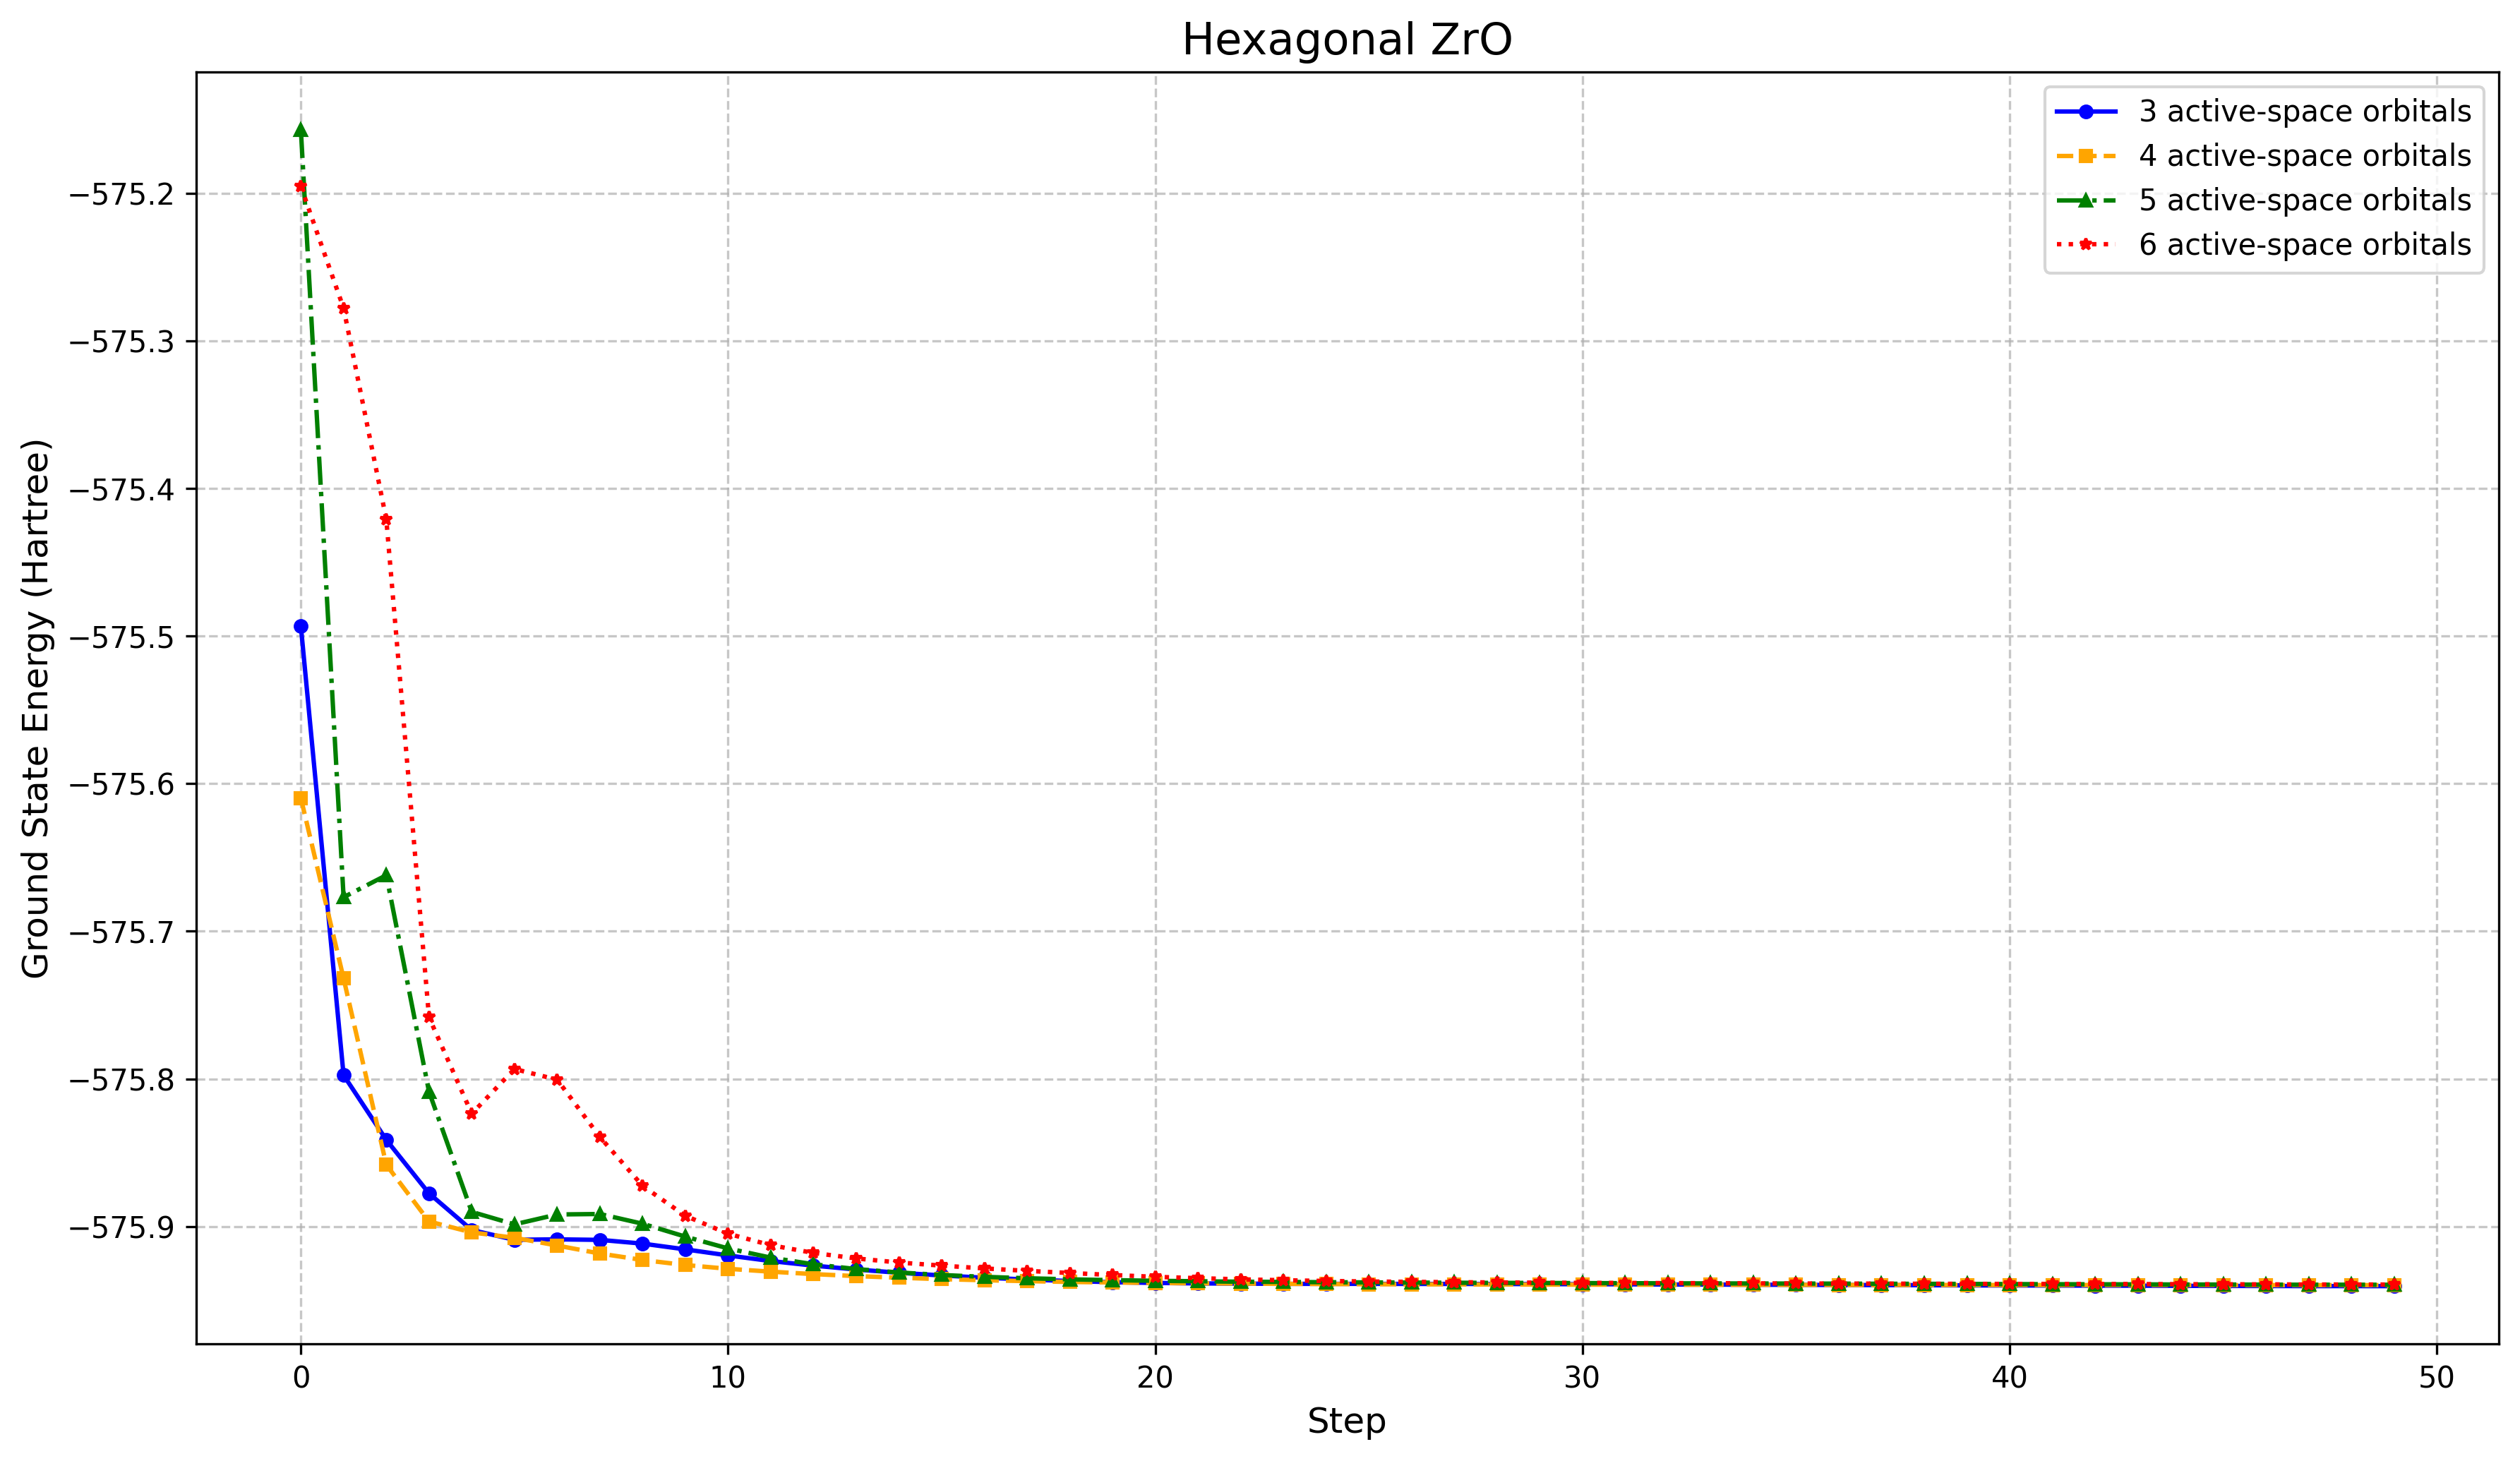

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# 原始数据
L1= [-575.4933, -575.7975, -575.8413, -575.87756, -575.9024, -575.909, -575.9087, -575.90906, -575.9116, -575.9155, -575.9196, -575.9234, -575.9265, -575.92914, -575.93134, -575.93317, -575.9347, -575.9359, -575.93695, -575.9377, -575.93823, -575.93854, -575.9387, -575.93884, -575.93884, -575.93884, -575.9389, -575.9389, -575.93896, -575.939, -575.9391, -575.93915, -575.9393, -575.93933, -575.93945, -575.9395, -575.93964, -575.9397, -575.93976, -575.9399, -575.93994, -575.94, -575.94006, -575.9401, -575.9402, -575.94025, -575.9403, -575.94037, -575.94037, -575.9404, -575.9404, -575.9405, -575.9405, -575.9405, -575.9405, -575.94055, -575.9406, -575.9406, -575.9407, -575.94073, -575.9408, -575.94086, -575.9409, -575.941, -575.94104, -575.9411, -575.94116, -575.94116, -575.9412, -575.9412, -575.9413, -575.94135, -575.9414, -575.94147, -575.9415, -575.9416, -575.94165, -575.94165, -575.9417, -575.9417, -575.9418, -575.9418, -575.94183, -575.94183, -575.94183, -575.94183, -575.94183, -575.94183, -575.94183, -575.94183, -575.94183, -575.94183, -575.94183, -575.9419, -575.9419, -575.9419, -575.9419, -575.9419, -575.9419, -575.9419]
L4= [-575.6098, -575.73193, -575.8582, -575.8966, -575.904, -575.90765, -575.9129, -575.9183, -575.9227, -575.9261, -575.92865, -575.9306, -575.93225, -575.9336, -575.9347, -575.93567, -575.9364, -575.937, -575.93756, -575.9379, -575.93823, -575.9385, -575.93866, -575.93884, -575.93896, -575.9391, -575.93915, -575.9392, -575.9393, -575.93933, -575.9394, -575.9394, -575.93945, -575.9395, -575.9395, -575.9395, -575.9396, -575.9396, -575.9396, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398, -575.9398]
L5= [-575.1571, -575.67694, -575.66205, -575.8087, -575.8901, -575.89856, -575.89185, -575.89154, -575.89813, -575.90686, -575.91486, -575.9211, -575.9256, -575.92883, -575.93115, -575.93286, -575.9341, -575.93506, -575.9358, -575.93634, -575.93677, -575.9371, -575.9374, -575.93756, -575.93774, -575.93787, -575.938, -575.9381, -575.9382, -575.93823, -575.93835, -575.9384, -575.9385, -575.93854, -575.9386, -575.93866, -575.9387, -575.9388, -575.93884, -575.9389, -575.939, -575.9391, -575.93915, -575.9392, -575.9393, -575.93933, -575.9394, -575.93945, -575.93945, -575.9395, -575.93945, -575.93945, -575.93945, -575.93945, -575.93945, -575.9395, -575.9395, -575.9396, -575.9396, -575.9396, -575.9396, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976]
#L6= [-575.27747, -575.5088, -575.4474, -575.7334, -575.833, -575.8611, -575.873, -575.87964, -575.88916, -575.90045, -575.91064, -575.9182, -575.9234, -575.9268, -575.92926, -575.93115, -575.9326, -575.9339, -575.9349, -575.9357, -575.9364, -575.93695, -575.93744, -575.93774, -575.93805, -575.93823, -575.9384, -575.93854, -575.93866, -575.9388, -575.93884, -575.93896, -575.939, -575.93915, -575.9392, -575.9393, -575.93933, -575.9394, -575.93945, -575.9395, -575.9395, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.93964, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.9397, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976, -575.93976]
L6= [-575.1954, -575.27795, -575.421, -575.75836, -575.82355, -575.79333, -575.80054, -575.8394, -575.8725, -575.89276, -575.9049, -575.91266, -575.9179, -575.92163, -575.9244, -575.9265, -575.9284, -575.93005, -575.9315, -575.93286, -575.9341, -575.935, -575.9358, -575.9364, -575.9369, -575.93726, -575.9375, -575.93774, -575.9379, -575.93805, -575.9382, -575.93823, -575.93835, -575.9384, -575.9385, -575.9386, -575.93866, -575.9387, -575.9388, -575.93884, -575.9389, -575.9389, -575.93896, -575.939, -575.9391, -575.93915, -575.9392, -575.9393, -575.9393, -575.93933, -575.93933, -575.93933, -575.93933, -575.93933, -575.93933, -575.93933, -575.93933, -575.9394, -575.9394, -575.9394, -575.9394, -575.93945, -575.93945, -575.93945, -575.93945, -575.93945, -575.93945, -575.93945, -575.93945, -575.93945, -575.93945, -575.93945, -575.9395, -575.9395, -575.9395, -575.9395, -575.9395, -575.9395, -575.9395, -575.9395, -575.9395, -575.9395, -575.9395, -575.9395, -575.9395, -575.9395, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396, -575.9396]







def process_list(lst):
    """处理列表，使其包含100个元素，截断或填充"""
    
    if len(lst) >= 50:
        return lst[:50]  # 截断到100个元素
    else:
        # 填充到100个元素，使用最后一个元素重复
        last_value = lst[-1] if lst else 0  # 避免空列表的情况
        return lst + [last_value] * (50 - len(lst))

# 处理列表数据
processed_L1 = process_list(L1)
processed_L4 = process_list(L4)
processed_L5 = process_list(L5)
processed_L6 = process_list(L6)

# 创建画布和坐标轴
plt.figure(figsize=(12, 7))

# 设置中文字体支持
#plt.rcParams["font.family"] = ["SimHei", "WenQuanYi Micro Hei", "Heiti TC"]

# 绘制三条折线
plt.plot(processed_L1, marker='o',color='blue', markersize=4, linestyle='-', linewidth=1.5, label='3 active-space orbitals')
plt.plot(processed_L4, marker='s',color='orange',markersize=4, linestyle='--', linewidth=1.5, label='4 active-space orbitals')
plt.plot(processed_L5, marker='^',color='green', markersize=4, linestyle='-.', linewidth=1.5, label='5 active-space orbitals')
plt.plot(processed_L6, marker='*',color='red', markersize=4, linestyle=':', linewidth=1.5, label='6 active-space orbitals')


# 添加标题和标签
plt.title('Hexagonal ZrO', fontsize=15)
plt.xlabel('Step', fontsize=12)
plt.ylabel('Ground State Energy (Hartree)', fontsize=12)

# 添加图例和网格
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)

# 设置y轴范围，突出显示数据差异
# min_val = min(min(processed_L1), min(processed_L4), min(processed_L5))
# max_val = max(max(processed_L1), max(processed_L4), max(processed_L5))
# plt.ylim(min_val - 0.01, max_val + 0.01)

plt.savefig('fig/HZrO-orb2.png')
# 显示图形
plt.tight_layout()  # 自动调整布局
plt.show()    

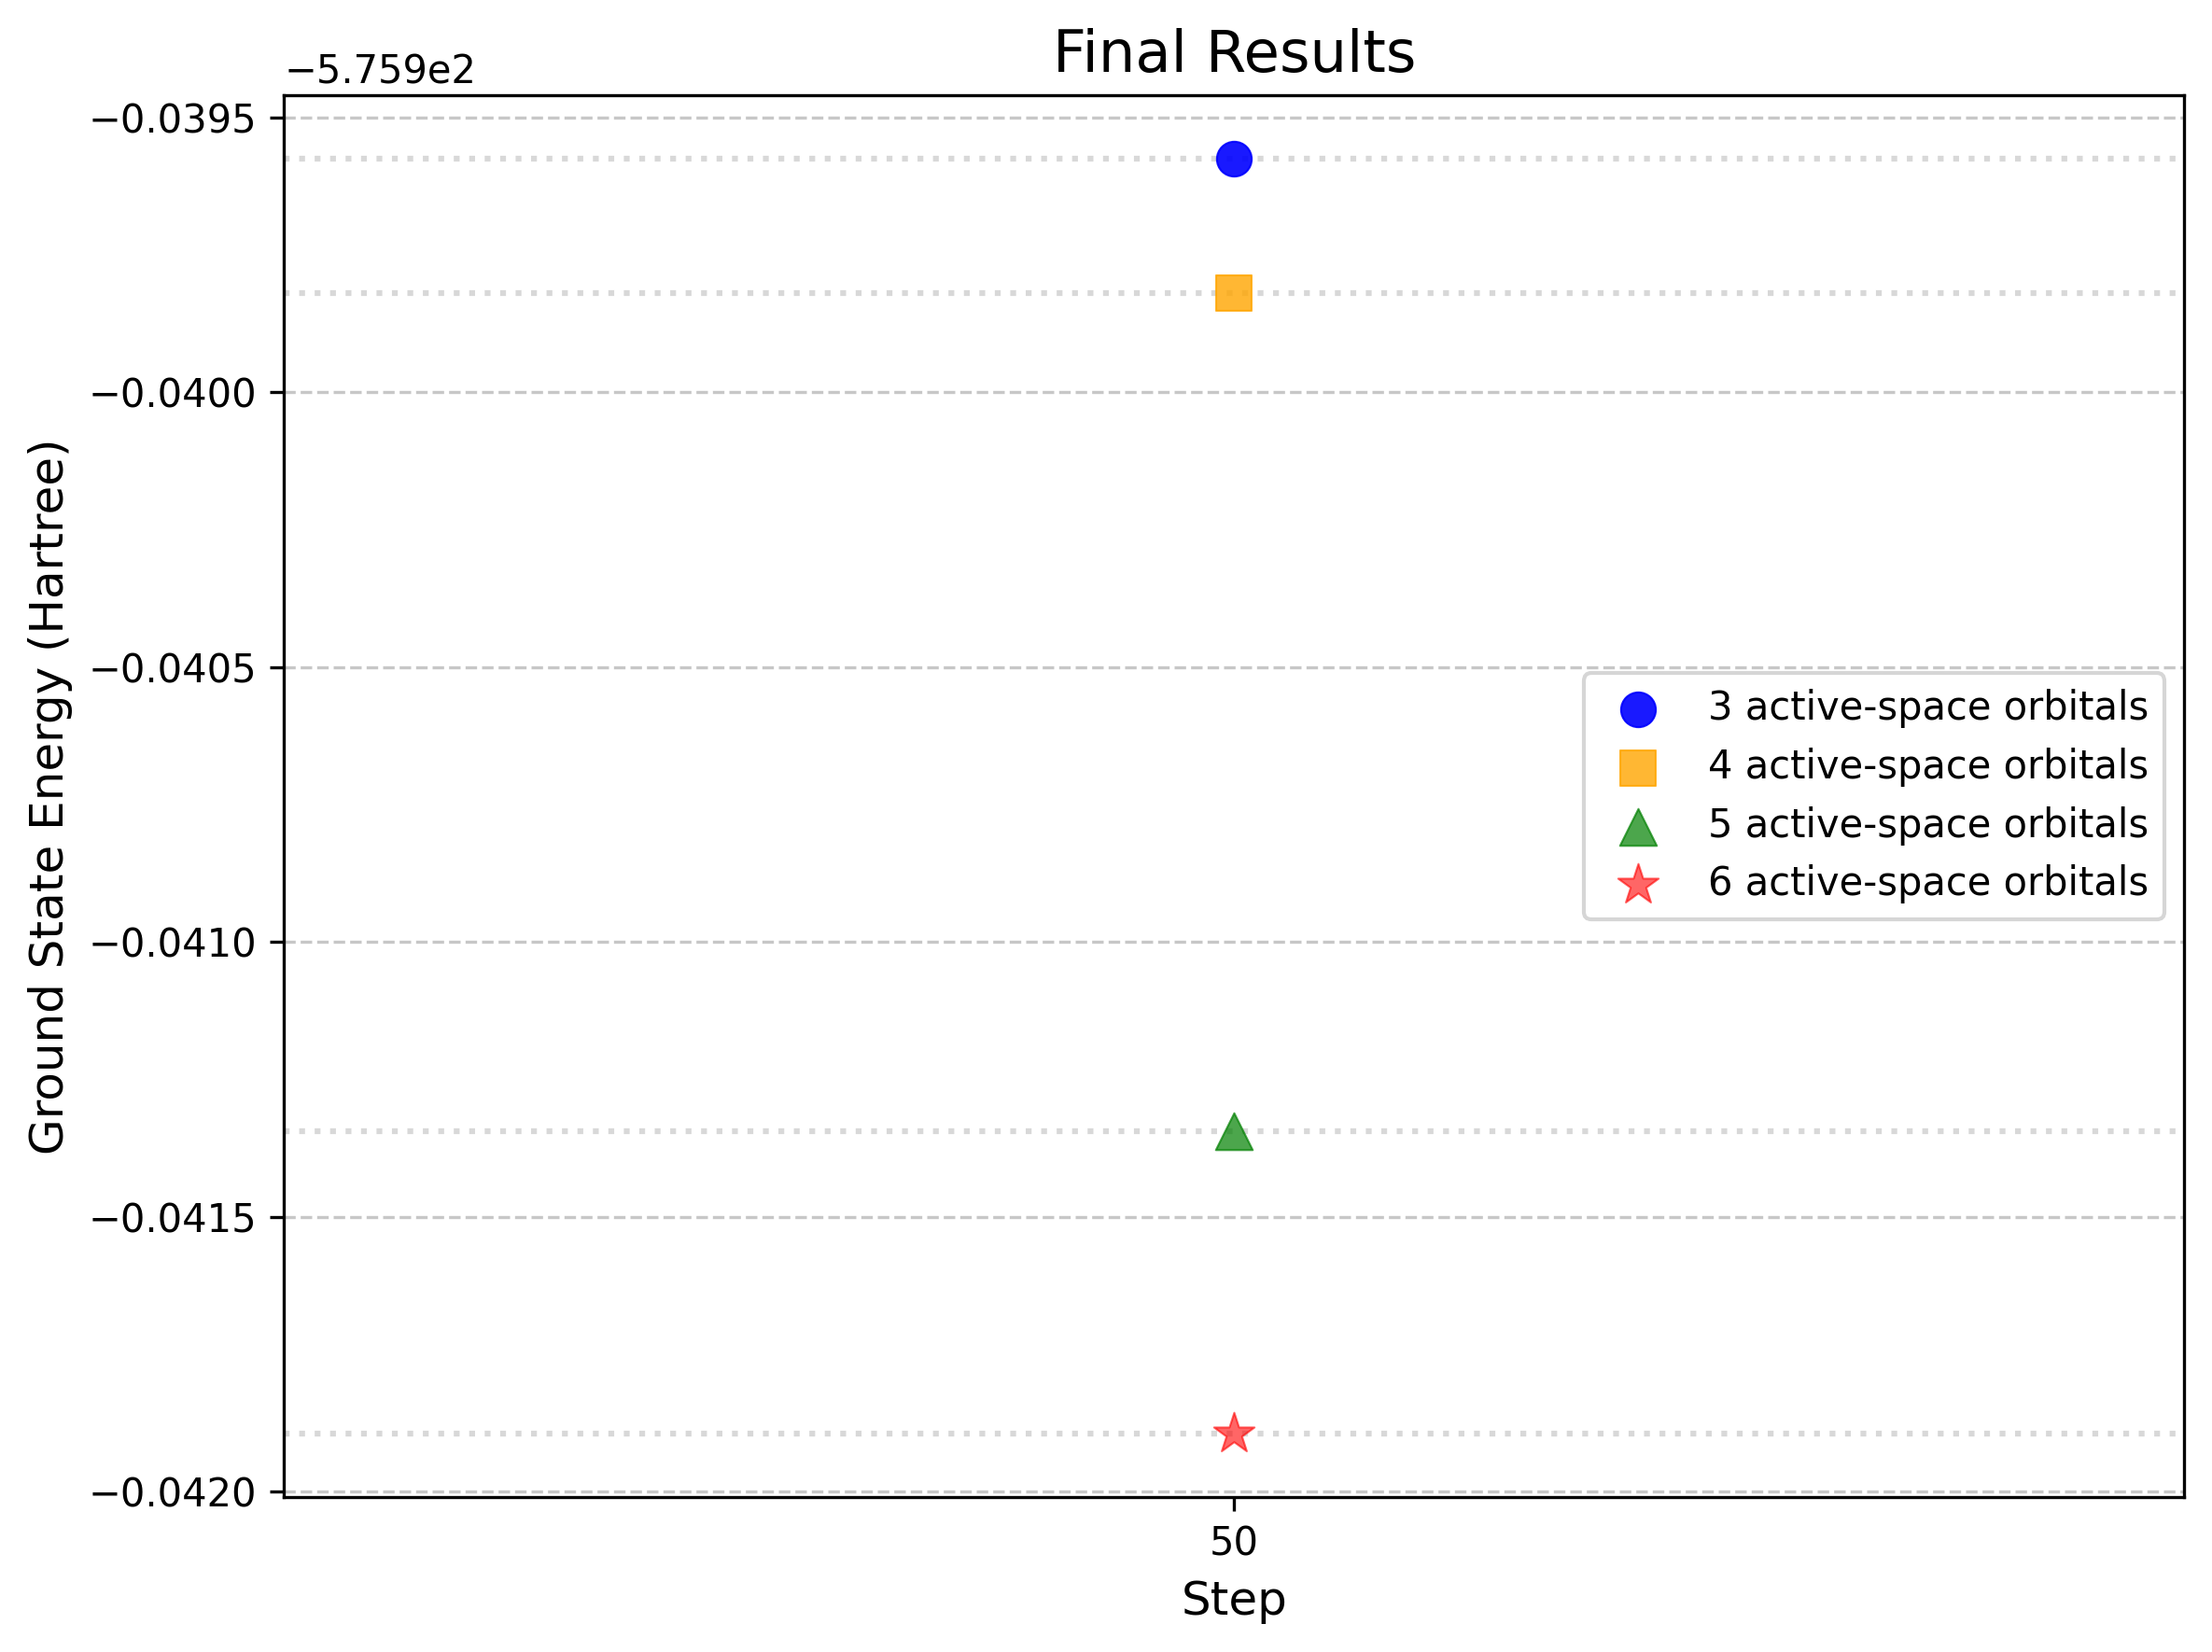

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# 设置图片清晰度
plt.rcParams['figure.dpi'] = 300

# 数据
x_position = 50  # 所有点的横坐标位置
energies = [-575.9395751953125, -575.9398193359375, -575.9413452148438, -575.94189453125]
labels = ['3 active-space orbitals', '4 active-space orbitals', '5 active-space orbitals', '6 active-space orbitals']
colors = ['blue', 'orange', 'green', 'red']
markers = ['o', 's', '^', '*']  # 圆形、正方形、三角形、五角星
sizes = [80, 80, 90, 120]  # 五角星需要更大的尺寸
zorders = [4, 3, 2, 1]  # 控制绘制顺序，确保五角星在最上层
alphas = [0.9, 0.8, 0.7, 0.6]  # 添加透明度，使重叠部分可见

# 创建图形
plt.figure(figsize=(8, 6))

# 绘制每个数据点
for energy, label, color, marker, size, zorder, alpha in zip(energies, labels, colors, markers, sizes, zorders, alphas):
    plt.scatter(x_position, energy, color=color, marker=marker, s=size, label=label, 
                zorder=zorder, alpha=alpha, linewidth=0.5)

# 添加标题和标签
plt.title('Final Results', fontsize=15)
plt.xlabel('Step', fontsize=12)
plt.ylabel('Ground State Energy (Hartree)', fontsize=12)

# 设置x轴刻度
plt.xticks([x_position])
plt.xlim(x_position - 0.1, x_position + 0.1)  # 严格限制x轴范围

# 添加网格和图例
plt.grid(True, linestyle='--', alpha=0.7, axis='y')  # 只显示y轴网格
plt.legend(loc='best')

# 添加水平参考线
for energy in energies:
    plt.axhline(y=energy, linestyle=':', color='gray', alpha=0.3, zorder=0)

# 调整布局
plt.tight_layout()

# 保存图像
# try:
#     plt.savefig('energy_points.png')
#     print("图像已成功保存为 'energy_points.png'")
# except Exception as e:
#     print(f"保存图像时出错: {e}")
plt.savefig('fig/HZrO-orb2-1.png')

# 显示图像
plt.show()  